
Figure 4 -- Final PI vs p for both models


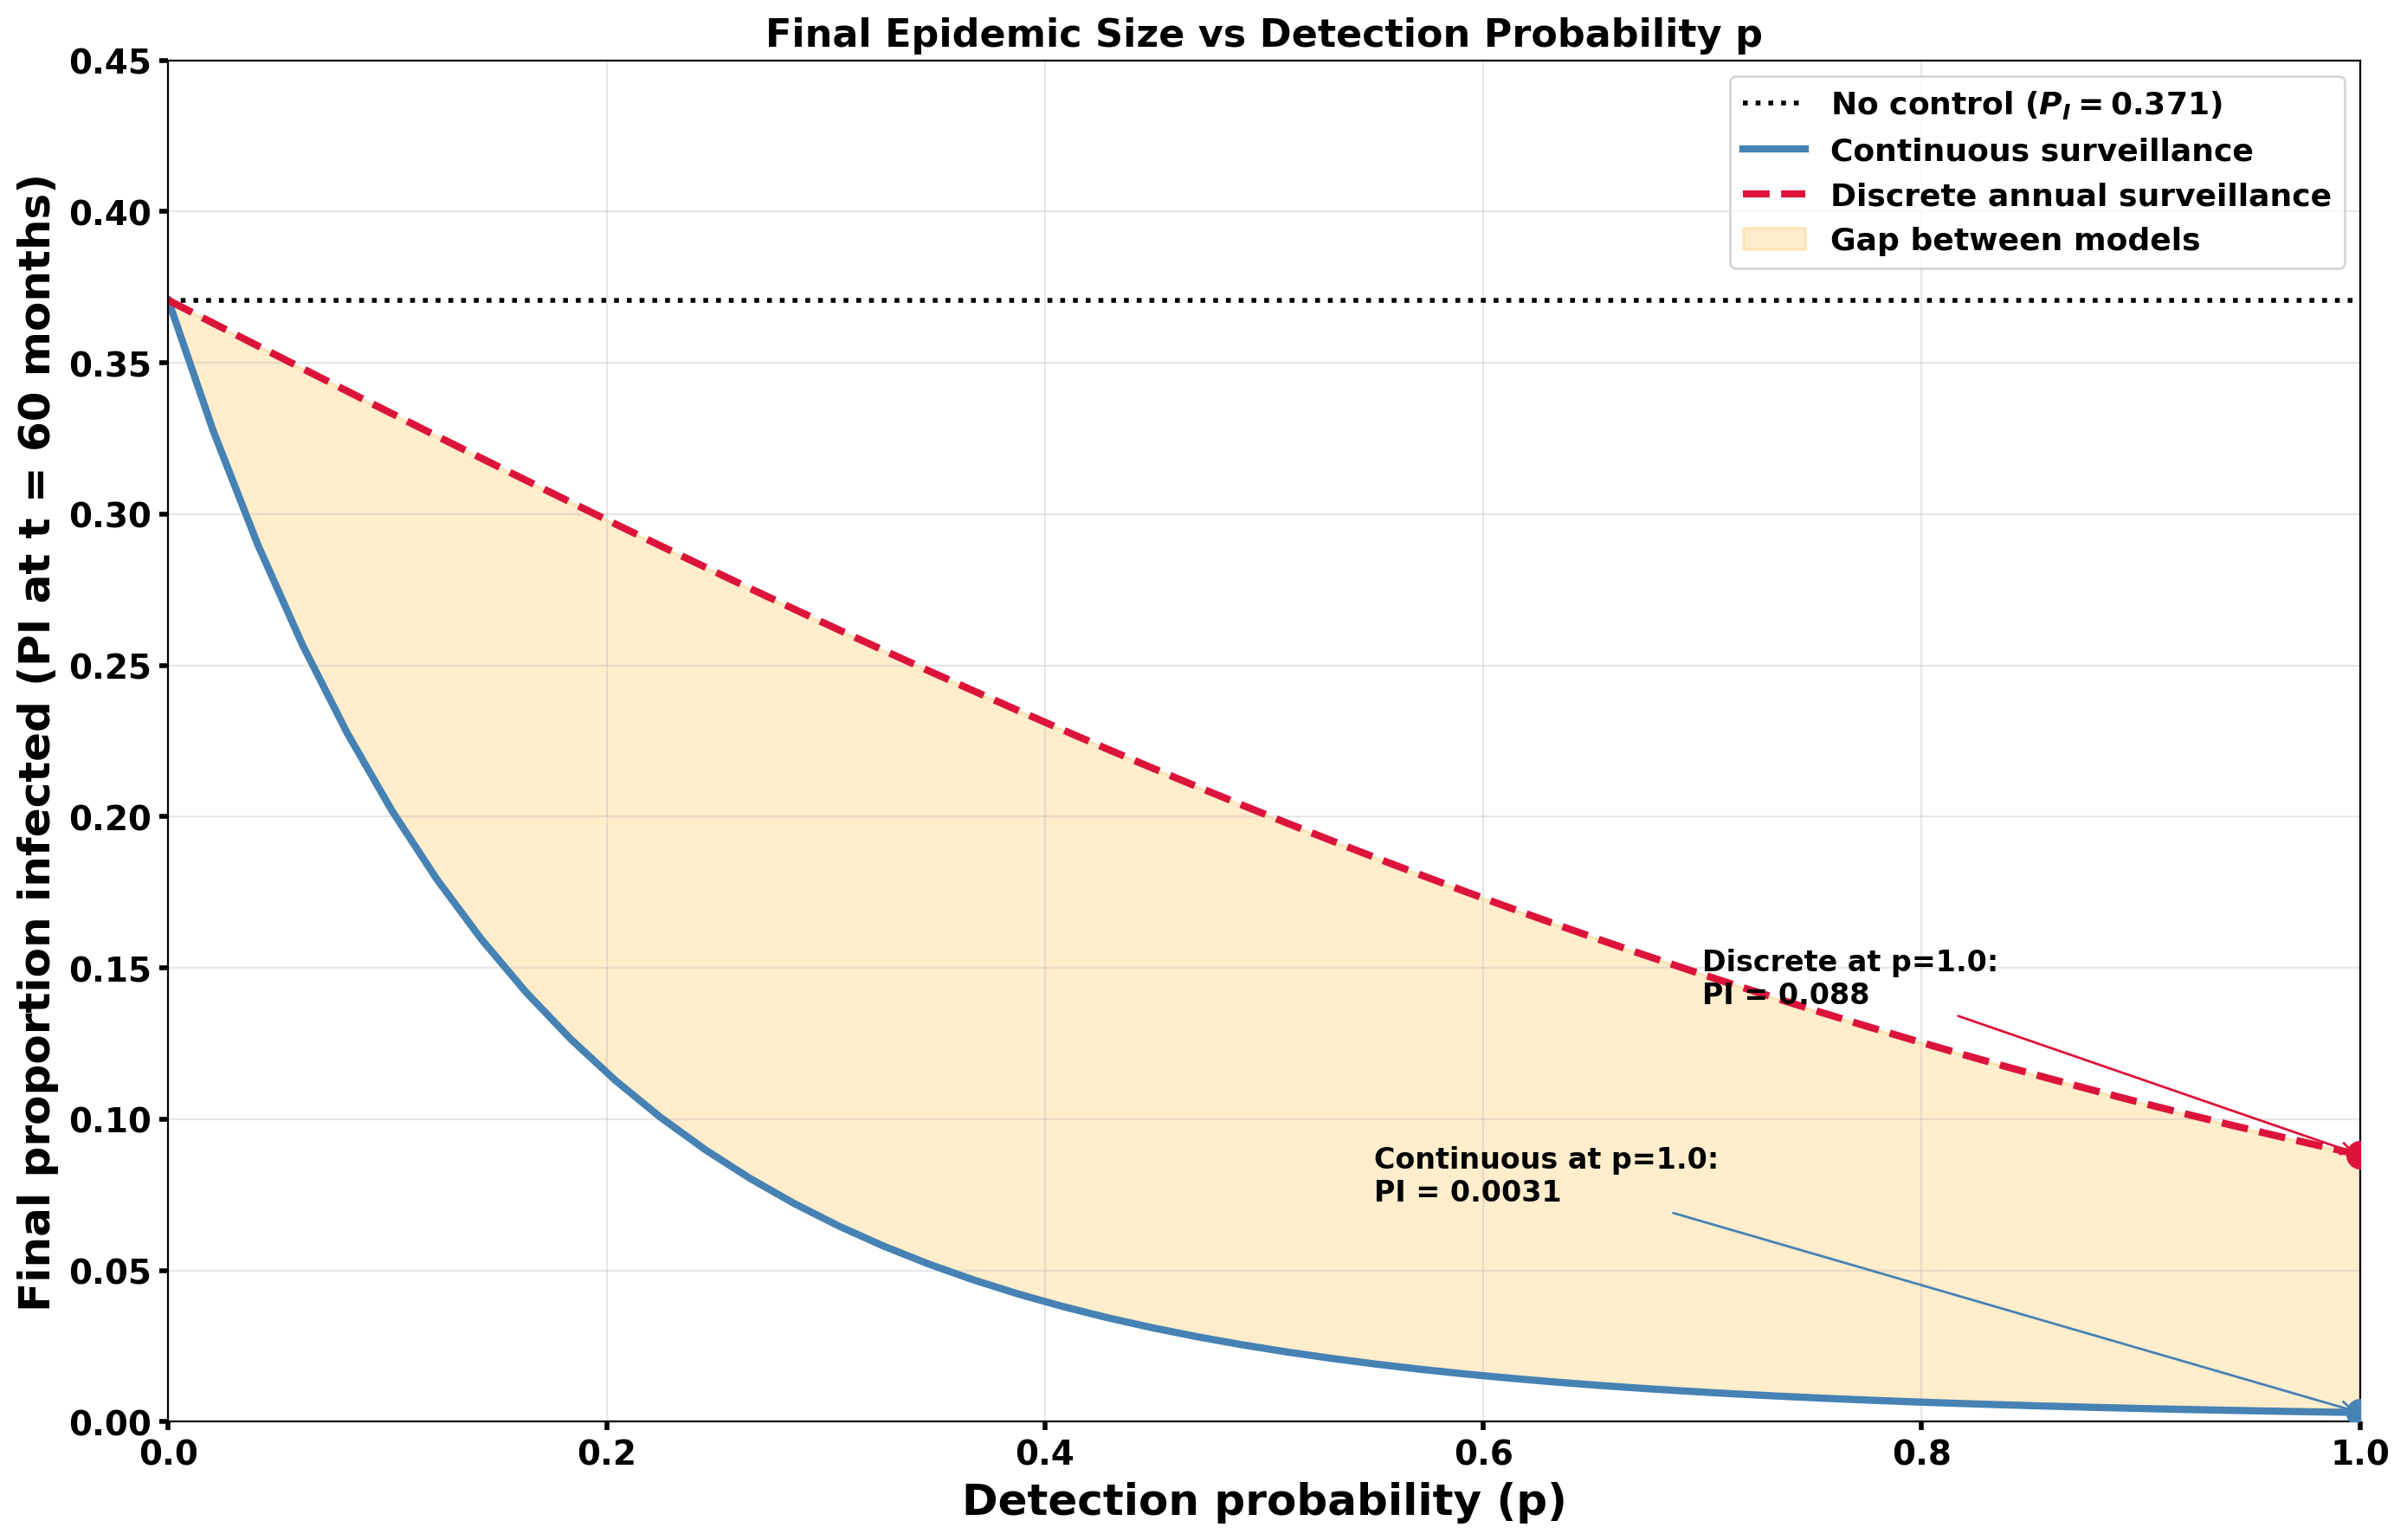

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp


# Posterior parameters from Best & Cunniffe (2026) 
beta = 0.82
rho  = 1.0 / 10.53
L    = 0.99

#  Lattice 
N_lattice = 625

# Simulation settings 
t_total       = 60
survey_interval = 12
n_surveys     = t_total // survey_interval
steps_per_year = 500

# Initial conditions
PE_init  = 1.0 / N_lattice
PS_init  = 1.0 - PE_init
PI_init  = 0.0
PSS_init = PS_init * PS_init
PSE_init = PS_init * PE_init
PSI_init = 0.0
PEE_init = PE_init * PE_init
PEI_init = 0.0
PII_init = 0.0


def sei_free(t, y, beta, rho, L):
    PS, PE, PSS, PSE, PSI, PEE, PEI = y
    PI = 1.0 - PS - PE

    if PS < 1e-12:
        qIS = 0.0
    else:
        qIS = PSI / PS

    inf_S  = (1.0 - L) * PI + L * qIS
    inf_SS = (1.0 - L) * PI + (3.0/4.0) * L * qIS
    inf_SI = (1.0 - L) * PI + (1.0/4.0)*L + (3.0/4.0)*L*qIS

    dPS = -beta * PS * inf_S
    dPE =  beta * PS * inf_S - rho * PE

    dPSS = -2.0 * beta * PSS * inf_SS
    dPSE = ( beta * PSS * inf_SS
            -beta * PSE * inf_SS
            -rho  * PSE)
    dPSI = ( rho  * PSE
            -beta * PSI * inf_SI)
    dPEE = ( 2.0 * beta * PSE * inf_SS
            -2.0 * rho  * PEE)
    dPEI = ( rho  * PEE
            +beta * PSI * inf_SI
            -rho  * PEI)

    return [dPS, dPE, dPSS, dPSE, dPSI, dPEE, dPEI]


def apply_annual_survey(state, p):
    PS, PE, PSS, PSE, PSI, PEE, PEI = state
    PI = 1.0 - PS - PE

    detected_I = p * PI
    PI_new = PI - detected_I

    removed_S = p * PSI
    removed_E = p * PEI

    PS_new = max(PS - removed_S, 0.0)
    PE_new = max(PE - removed_E, 0.0)
    PI_new = max(PI_new, 0.0)

    fS = PS_new / PS if PS > 1e-12 else 0.0
    fE = PE_new / PE if PE > 1e-12 else 0.0
    fI = PI_new / PI if PI > 1e-12 else 0.0

    PSS_new = max(PSS * fS * fS, 0.0)
    PSE_new = max(PSE * fS * fE, 0.0)
    PSI_new = max(PSI * fS * fI, 0.0)
    PEE_new = max(PEE * fE * fE, 0.0)
    PEI_new = max(PEI * fE * fI, 0.0)

    new_state = [PS_new, PE_new,
                 PSS_new, PSE_new, PSI_new,
                 PEE_new, PEI_new]

    removed = {
        'I': detected_I,
        'S': removed_S,
        'E': removed_E,
        'total': detected_I + removed_S + removed_E
    }

    return new_state, removed


def run_discrete_model(p, beta=beta, rho=rho, L=L):

    state = [PS_init, PE_init,
             PSS_init, PSE_init, PSI_init,
             PEE_init, PEI_init]

    all_t  = []
    all_PS = []
    all_PE = []
    all_PI = []
    all_PV = []

    t_current = 0.0
    total_removed = 0.0

    for survey_num in range(n_surveys):

        t_span = [t_current, t_current + survey_interval]
        t_eval_chunk = np.linspace(
            t_current, t_current + survey_interval,
            steps_per_year
        )

        sol = solve_ivp(
            sei_free,
            t_span,
            state,
            args=(beta, rho, L),
            t_eval=t_eval_chunk,
            method='Radau',
            rtol=1e-8, atol=1e-10
        )

        PS_chunk = sol.y[0]
        PE_chunk = sol.y[1]
        PI_chunk = 1.0 - PS_chunk - PE_chunk
        PV_chunk = np.zeros_like(PS_chunk)

        all_t.append(sol.t)
        all_PS.append(PS_chunk)
        all_PE.append(PE_chunk)
        all_PI.append(PI_chunk)
        all_PV.append(PV_chunk)

        state_end = [
            sol.y[0][-1],
            sol.y[1][-1],
            sol.y[2][-1],
            sol.y[3][-1],
            sol.y[4][-1],
            sol.y[5][-1],
            sol.y[6][-1],
        ]

        new_state, removed = apply_annual_survey(state_end, p)
        total_removed += removed['total']

        t_current += survey_interval
        state = new_state

    t_full  = np.concatenate(all_t)
    PS_full = np.concatenate(all_PS)
    PE_full = np.concatenate(all_PE)
    PI_full = np.concatenate(all_PI)
    PV_full = np.concatenate(all_PV)

    return t_full, PS_full, PE_full, PI_full, PV_full, total_removed


def sei_continuous(t, y, beta, rho, L, r, c, p):
    PS, PE, PI, PSS, PSE, PSI, PEE, PEI, PII = y
    PV = 1.0 - PS - PE - PI

    if PS < 1e-12:
        qIS = 0.0
    else:
        qIS = PSI / PS

    if PE < 1e-12:
        qIE = 0.0
    else:
        qIE = PEI / PE

    pr = p * r
    pc = p * c

    inf_S  = (1.0 - L)*PI + L*qIS
    inf_SS = (1.0 - L)*PI + (3.0/4.0)*L*qIS
    inf_SI = (1.0 - L)*PI + (1.0/4.0)*L + (3.0/4.0)*L*qIS

    dPS = -beta*PS*inf_S - pc*PSI
    dPE =  beta*PS*inf_S - rho*PE - pc*PEI
    dPI =  rho*PE - pr*PI

    dPSS = -2.0*beta*PSS*inf_SS - 2.0*pc*PSS*qIS
    dPSE = ( beta*PSS*inf_SS - beta*PSE*inf_SS
            -rho*PSE - pc*PSE*qIS - pc*PEI*qIE)
    dPSI = ( rho*PSE - beta*PSI*inf_SI
            -pr*PSI - pc*PSI*((1.0/4.0)+(3.0/4.0)*qIS))
    dPEE = ( 2.0*beta*PSE*inf_SS - 2.0*rho*PEE
            -2.0*pc*PEE*qIE)
    dPEI = ( rho*PEE + beta*PSI*inf_SI
            -rho*PEI - pr*PEI
            -pc*PEI*((1.0/4.0)+(3.0/4.0)*qIE))

    dPII = 2.0*rho*PEI - 2.0*pr*PII

    return [dPS,dPE,dPI,dPSS,dPSE,dPSI,dPEE,dPEI,dPII]


def run_continuous_model(p, r=0.2, c=0.2):
    y0_cont = [PS_init, PE_init, PI_init,
               PSS_init, PSE_init, PSI_init,
               PEE_init, PEI_init, PII_init]

    t_eval_cont = np.linspace(0, t_total, 3000)

    sol = solve_ivp(
        sei_continuous,
        [0, t_total], y0_cont,
        args=(beta, rho, L, r, c, p),
        t_eval=t_eval_cont,
        method='Radau', rtol=1e-8, atol=1e-10
    )

    return (sol.t, sol.y[0], sol.y[1], sol.y[2],
            1.0 - sol.y[0] - sol.y[1] - sol.y[2])


# =============================================================
# FIGURE 4 -- Visualization improvements ONLY
# =============================================================

p_range = np.linspace(0.0, 1.0, 50)

final_PI_discrete   = []
final_PI_continuous = []

print("\nFigure 4 -- Final PI vs p for both models")

for pv in p_range:
    _, _, _, PI_d, _, _ = run_discrete_model(pv)
    final_PI_discrete.append(PI_d[-1])

    _, _, _, PI_c, _ = run_continuous_model(pv)
    final_PI_continuous.append(PI_c[-1])

final_PI_discrete   = np.array(final_PI_discrete)
final_PI_continuous = np.array(final_PI_continuous)

_, _, _, PI_nc, _, _ = run_discrete_model(0.0)
no_control_final = PI_nc[-1]

# ------------------- PLOT STYLE ENHANCEMENT ONLY -------------------
plt.rcParams.update({
    "font.weight": "bold",
    "axes.labelweight": "bold"
})

fig4, ax4 = plt.subplots(figsize=(14, 9), dpi=200)

ax4.axhline(y=no_control_final,
            color='black', linewidth=2,
            linestyle=':',
            label=f'No control ($P_I = {no_control_final:.3f}$)')

ax4.plot(p_range, final_PI_continuous,
         color='steelblue', linewidth=3,
         label='Continuous surveillance')

ax4.plot(p_range, final_PI_discrete,
         color='crimson', linewidth=3,
         linestyle='--',
         label='Discrete annual surveillance')

ax4.fill_between(p_range,
                 final_PI_continuous,
                 final_PI_discrete,
                 alpha=0.2, color='orange',
                 label='Gap between models')

ax4.scatter([1.0], [final_PI_discrete[-1]],
            color='crimson', s=120, zorder=5)

ax4.scatter([1.0], [final_PI_continuous[-1]],
            color='steelblue', s=120, zorder=5)

ax4.annotate(
    f'Discrete at p=1.0:\nPI = {final_PI_discrete[-1]:.3f}',
    xy=(1.0, final_PI_discrete[-1]),
    xytext=(0.70, final_PI_discrete[-1] + 0.05),
    fontsize=12, fontweight='bold',
    arrowprops=dict(arrowstyle='->', color='crimson')
)

ax4.annotate(
    f'Continuous at p=1.0:\nPI = {final_PI_continuous[-1]:.4f}',
    xy=(1.0, final_PI_continuous[-1]),
    xytext=(0.55, final_PI_continuous[-1] + 0.07),
    fontsize=12, fontweight='bold',
    arrowprops=dict(arrowstyle='->', color='steelblue')
)

ax4.set_title(
    'Final Epidemic Size vs Detection Probability p',
    fontsize=16, fontweight='bold'
)

ax4.set_xlabel('Detection probability (p)',
               fontsize=18, fontweight='bold')

ax4.set_ylabel('Final proportion infected (PI at t = 60 months)',
               fontsize=18, fontweight='bold')

ax4.tick_params(axis='both', labelsize=14, width=2)

ax4.set_xlim([0, 1])
ax4.set_ylim([0, 0.45])

ax4.legend(fontsize=13, loc='upper right')
ax4.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('discrete_figure4_pI_vs_p.png',
            dpi=300, bbox_inches='tight')

plt.show()